# 01 · Exploring the listings

First look at the 3.5M listings from [tinixai/vietnam-real-estates](https://huggingface.co/datasets/tinixai/vietnam-real-estates) (June 2025 to March 2026). The goal is to find out what needs cleaning before any model sees the data.

Run `python scripts/download.py` first.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from soi_gia_nha.data import load_raw

pd.set_option('display.precision', 3)
cols = ['name', 'description', 'property_type_name', 'province_name', 'district_name',
        'ward_name', 'price', 'area', 'bedroom_count', 'floor_count', 'frontage_width',
        'road_width', 'published_at']
df = load_raw(columns=cols)
df['price'] = pd.to_numeric(df['price'], errors='coerce')  # stored as text in the parquet
df['published_at'] = pd.to_datetime(df['published_at'], errors='coerce')
df.shape

(3500744, 13)

## What is in there

In [2]:
df['property_type_name'].value_counts()

property_type_name
Nhà                     1575536
Đất                      832766
Căn hộ chung cư          762800
Biệt thự/Nhà liền kề     269782
Shophouse                 59860
Name: count, dtype: int64

In [3]:
df['province_name'].value_counts().head(10)

province_name
Hồ Chí Minh          1357526
Hà Nội               1140542
Đà Nẵng               185973
Bình Dương            150377
Khánh Hòa              98377
Hải Phòng              72788
Hưng Yên               65223
Đồng Nai               59543
Long An                47125
Bà Rịa - Vũng Tàu      45885
Name: count, dtype: int64

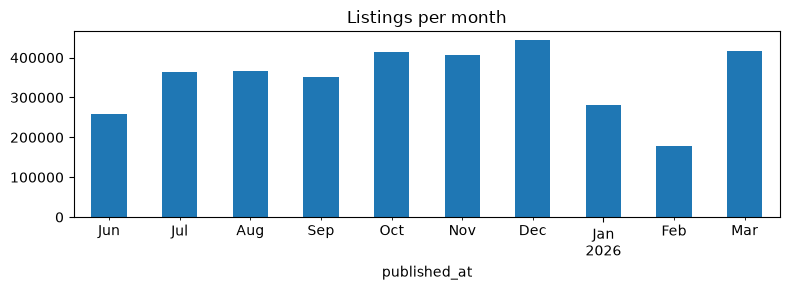

In [4]:
monthly = df['published_at'].dt.to_period('M').value_counts().sort_index()
monthly.plot.bar(figsize=(8, 3), title='Listings per month')
plt.tight_layout()

## Missing values

Only area is always filled. The physical details are mostly empty.

In [5]:
df.isna().mean().sort_values(ascending=False).to_frame('missing')

,missing
road_width,8.086e-01
floor_count,7.690e-01
frontage_width,4.932e-01
bedroom_count,4.571e-01
ward_name,1.419e-01
price,6.241e-02
district_name,2.912e-02
published_at,6.291e-03
area,1.143e-06
province_name,0.000e+00


That is the main reason to read the free-text description later: it often mentions the floors, the alley width or the legal papers that the structured columns leave blank.

In [6]:
keywords = ['sổ hồng', 'sổ đỏ', 'hẻm xe hơi', 'ô tô', 'nội thất', 'mặt tiền', 'chính chủ']
desc = df['description'].str.lower()
pd.Series({k: desc.str.contains(k, regex=False).mean() for k in keywords}, name='share')

sổ hồng       0.204
sổ đỏ         0.211
hẻm xe hơi    0.040
ô tô          0.205
nội thất      0.260
mặt tiền      0.328
chính chủ     0.263
Name: share, dtype: float64

## Prices that cannot be right

In [7]:
print('missing price :', df['price'].isna().sum())
print('price <= 0    :', (df['price'] <= 0).sum())
df['price'].quantile([0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]) / 1e9  # billion VND

missing price : 218494
price <= 0    : 57320


0.001      0.00
0.010      0.00
0.050      1.15
0.500      7.30
0.950     48.00
0.990    136.00
0.999    530.00
Name: price, dtype: float64

In [8]:
ppm = df['price'] / df['area'] / 1e6  # million VND per m2
ppm.quantile([0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

0.001       0.000
0.010       0.000
0.050       6.181
0.500      95.706
0.950     366.154
0.990     603.732
0.999    1182.260
dtype: float64

The bottom percentiles are near zero: those are placeholders (`0`, `1`) or prices typed per m2 instead of in total. The top end includes land plots listed in hectares. Both need a filter on price per m2, by property type.

In [9]:
df['area'].quantile([0.001, 0.01, 0.5, 0.99, 0.999])

0.001       14.0
0.010       25.0
0.500       80.0
0.990     2222.0
0.999    24630.0
Name: area, dtype: float64

## Reposts

The same property is often listed again and again. If a repost lands in the training set and the original in the test set, the model looks better than it is.

In [10]:
print('same title, price, area:', df.duplicated(['name', 'price', 'area']).mean())
print('same description       :', df.duplicated(['description']).mean())

same title, price, area: 0.24810725948541223


same description       : 0.13112412675705507


## Hanoi and Ho Chi Minh City

The first version focuses on these two cities.

In [11]:
hh = df[df['province_name'].isin(['Hà Nội', 'Hồ Chí Minh'])]
print(len(hh), 'listings,', f"{len(hh) / len(df):.0%} of the data")
hh.groupby(['province_name', 'property_type_name']).size().unstack(0)

2498068 listings, 71% of the data


province_name,Hà Nội,Hồ Chí Minh
property_type_name,,
Biệt thự/Nhà liền kề,92936,62666
Căn hộ chung cư,303589,279948
Nhà,549408,842922
Shophouse,13075,9880
Đất,181534,162110


In [12]:
ok = hh[(hh['price'] > 0) & hh['area'].between(10, 1000)]
(ok.assign(ppm=ok['price'] / ok['area'] / 1e6)
   .groupby(['province_name', 'property_type_name'])['ppm']
   .median().unstack(0).round(0))  # median million VND / m2

province_name,Hà Nội,Hồ Chí Minh
property_type_name,,
Biệt thự/Nhà liền kề,267.0,172.0
Căn hộ chung cư,80.0,66.0
Nhà,249.0,130.0
Shophouse,190.0,127.0
Đất,84.0,70.0


In [13]:
print('missing district:', hh['district_name'].isna().mean())
print('missing ward    :', hh['ward_name'].isna().mean())

missing district: 0.03347787169924918
missing ward    : 0.14340122046317394


## Takeaways

1. Cast `price` to a number, drop missing and non-positive prices.
2. Drop impossible price per m2 and extreme areas, per property type.
3. Remove reposts **before** splitting train and test.
4. Split by time (train on older listings, test on newer ones), the way the tool is actually used.
5. Recover missing details from the description text.
6. Location matters most and is missing at ward level for some listings, so the model needs a district-level fallback.